# Biweekly-window error scorecard

## Purpose

Compare hindcast skill across lead windows (week1-2, week3-4, week5-6, week7-8; day 1 = initial date) for atmosphere and land variables, CTRL10 vs CAPT10 vs DART40, in both seasons. Each heat-map cell holds four triangles, one per window: top week1-2, right week3-4, bottom week5-6, left week7-8.

## Inputs

Member output of the hindcasts in `util/bias_metrics.py` under `post/<atm|lnd>/180x360_aave/ts/`, read through `util.model_daily`, each variable sampled so model and reference describe the same time (see Notes): 00Z-24Z daily means from `atm/.../ts/daily_mean` (PSL, TREFHT, TS, 10-m wind speed, PRECT, FLUT, surface fluxes) and the ELM `lnd/.../ts/daily` series, and 00Z instantaneous states from `ts/daily_00z` (U, V, T, Q, Z on pressure levels, which exist only as once-daily 00Z output) verified against ERA5 at 00Z. References under `OBSERVATION_ROOT`: ERA5 (PSL; U, V, T, Q, Z at 200, 500, 700, 850, 925 hPa; TREFHT; skin temperature TS; 10-m wind speed; surface latent and sensible heat and net shortwave, downward shortwave, and downward longwave radiation; land: TREFHT for TSA, skin temperature TS for TG, LHFLX, SHFLX), GPM IMERG (PRECT), NOAA interpolated OLR (FLUT), ESA CCI soil moisture (top 5 cm). Land variables are scored over land; pressure-level variables only where the level is above ground (ERA5 surface-pressure climatology of the season's months above the level), which removes 850 and 925 hPa over Antarctica, Tibet, the Andes, and Greenland (and 925 hPa over other high terrain).

## Metrics

- **Anomaly PCC**: centered, cos-latitude weighted pattern correlation of window-mean anomalies; model and reference anomalies are both taken from the same reference climatology of those days.
- **MSSS**: mean-square skill score of the window-mean ensemble mean against the climatology forecast, `1 - (RMSE / RMSE_clim)^2`, where `RMSE_clim` is the RMSE of the reference climatology of those days. 1 = perfect, 0 = no better than climatology, negative = worse (blue = beats climatology). Every cell, CTRL included, is scored on the same absolute scale.
- **CRPSS**: skill of the whole ensemble, `1 - CRPS / CRPS_clim`. CRPS is the fair CRPS of the members' window means at each gridpoint (corrected for ensemble size, so 10- and 40-member ensembles compare fairly), area-averaged; the reference is the climatological ensemble, each climatology year's window means. It rewards an ensemble that is both accurate and has the right spread; mean bias counts in full.
- **Mean bias** (`REMOVE_MEAN_BIAS`): optionally remove the region's area-mean bias from both the model and the climatology forecast before the RMSE (centered RMSE; CRPS is unaffected). A uniform offset, such as the EAM-DART global surface-pressure loss in PSL and Z500, otherwise dominates the RMSE; the bias itself stays in the table (`bias`).

## Climatology

One shared period for every variable (`CLIM_YEARS`, default 2001-2017, the overlap of all reference records), leaving out the verified year (`CLIM_EXCLUDE_YEARS`). Daily references are averaged per calendar day and smoothed with a 31-day running mean; ERA5 TREFHT, TS, LHFLX, and SHFLX, archived daily only for 2011-2012, use the ERA5 monthly climatology interpolated to days.

## Outputs

Window-mean NetCDF caches and the score table under `DIAGNOSTIC_OUTPUT_ROOT/data/fcst_window_scorecard/`; one figure per option (`fig_window_scorecard_sub_list_<region>.pdf`, key variables; `fig_window_scorecard_full_list_<region>.pdf`, every variable), both seasons in each, with its caption (`.caption.txt`) under `DIAGNOSTIC_OUTPUT_ROOT/figure/fcst_window_scorecard/`. Review the user setup, then run the notebook from top to bottom.

## 1. Libraries

In [1]:
# Pick up edits to util/ modules without restarting the kernel.
%load_ext autoreload
%autoreload 2

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

## 2. User setup

Paths; the seasons and experiments compared, variables, regions, climatology period, and run options. Edit this cell for normal changes.

In [2]:
INPUT_DATA_ROOT = Path("/compyfs/zhan391/v3_dart_cda_scratch")
WORK_DIR = Path("/compyfs/zhan391/work_package/e3sm_dart_analysis")
DIAGNOSTIC_OUTPUT_ROOT = Path("/compyfs/www/zhan391/e3sm_dart/diag_dart_2026")
OBSERVATION_ROOT = Path("/compyfs/zhan391/acme_init/Observations")  # observations (shared archive)
LAND_SUPPORT_DIR = Path("/compyfs/zhan391/acme_init/lnd_sea_mask")  # land mask
WORKFLOW_NAME = "fcst_window_scorecard"

# What to compare: season -> experiments (the CTRL run is the RMSE baseline).
CASES = {
    "S0": ("CTRL10-S0", "CAPT10-S0", "DART40-S0"),  # Jan-Feb 2012
    "S1": ("CTRL10-S1", "CAPT10-S1", "DART40-S1"),  # Jun-Jul 2012
}

# Variables processed and scored; each is cached separately, so adding one later
# only computes that one.
LEVELS = (200, 500, 700, 850, 925)  # hPa
UPPER_AIR = tuple(f"{name}{level}" for name in ("U", "V", "T", "Q", "Z") for level in LEVELS)
SURFACE = ("PSL", "TREFHT", "TS", "WSPD10", "PRECT", "FLUT", "LHFLX", "SHFLX", "FSNS", "FSDS", "FLDS")
LAND = ("TSA", "TG", "SOILM_5CM", "EFLX_LH_TOT", "FSH")
VARIABLES = SURFACE + UPPER_AIR + LAND

# global, land, ocean, Tropics, CONUS, NHMidLat, NINO3.4, MAR_CONT (one figure each)
REGIONS = ("global",)

CLIM_YEARS = (2001, 2017)  # shared climatology period for every variable
CLIM_EXCLUDE_YEARS = (2012,)  # leave the verified year out
MIN_DAYS = 10  # window days a gridpoint needs (of 14) where the reference has gaps
REMOVE_MEAN_BIAS = False  # True: score centered RMSE (region-mean bias removed)

MAX_MEMBERS = None  # e.g. 2 for a quick test; caches record the ensemble size
FORCE_COMPUTE = False #True
SHOW = True  # figure settings are at the top of each figure cell

## 3. Driver: read, process, and save data

Reuse valid window-mean caches or build missing ones, then score every window and save the table.

In [3]:
repo = WORK_DIR.resolve()
if str(repo / "diagnostic") not in sys.path:
    sys.path.insert(0, str(repo / "diagnostic"))
from configs.output_paths import workflow_output_dirs
from util.forecast_ensemble_ts import REGIONS as AVAILABLE_REGIONS
from util.forecast_window_scorecard import build_window_means, window_scores

unknown = set(REGIONS) - set(AVAILABLE_REGIONS)
if unknown:
    raise ValueError(f"Unknown regions {sorted(unknown)}; choose from {list(AVAILABLE_REGIONS)}")
variables = VARIABLES
data_dir, figure_dir = workflow_output_dirs(WORKFLOW_NAME, output_root=DIAGNOSTIC_OUTPUT_ROOT)

window_means, registries, failures = build_window_means(
    CASES, variables, data_root=INPUT_DATA_ROOT, reference_root=OBSERVATION_ROOT,
    land_support_dir=LAND_SUPPORT_DIR, cache_dir=data_dir, clim_years=CLIM_YEARS,
    clim_exclude_years=CLIM_EXCLUDE_YEARS, min_days=MIN_DAYS, max_members=MAX_MEMBERS,
    force_compute=FORCE_COMPUTE,
)
if failures:
    print(f"\n{len(failures)} request(s) failed and are skipped below:")
    for season, variable, error in failures:
        print(f"  {season} {variable}: {error}")

scores = window_scores(window_means, regions=REGIONS, landmask_file=LAND_SUPPORT_DIR / "landmask_1x1.nc",
                       remove_mean_bias=REMOVE_MEAN_BIAS)
suffix = "_centered" if REMOVE_MEAN_BIAS else ""
table_path = data_dir / f"window_scores{suffix}.csv"
scores.to_csv(table_path, index=False)
print(f"[TABLE] {table_path}")

/qfs/people/zhan391/.conda/envs/e3sm_analysis/lib/python3.12/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


[REUSE] S0 PSL reference
[REUSE] S0 PSL CTRL10-S0
[REUSE] S0 PSL CAPT10-S0
[REUSE] S0 PSL DART40-S0
[REUSE] S0 TREFHT reference
[REUSE] S0 TREFHT CTRL10-S0
[REUSE] S0 TREFHT CAPT10-S0
[REUSE] S0 TREFHT DART40-S0
[REUSE] S0 TS reference
[REUSE] S0 TS CTRL10-S0
[REUSE] S0 TS CAPT10-S0
[REUSE] S0 TS DART40-S0
[REUSE] S0 WSPD10 reference
[REUSE] S0 WSPD10 CTRL10-S0
[REUSE] S0 WSPD10 CAPT10-S0
[REUSE] S0 WSPD10 DART40-S0
[REUSE] S0 PRECT reference
[REUSE] S0 PRECT CTRL10-S0
[REUSE] S0 PRECT CAPT10-S0
[REUSE] S0 PRECT DART40-S0
[REUSE] S0 FLUT reference
[REUSE] S0 FLUT CTRL10-S0
[REUSE] S0 FLUT CAPT10-S0
[REUSE] S0 FLUT DART40-S0
[REUSE] S0 LHFLX reference
[REUSE] S0 LHFLX CTRL10-S0
[REUSE] S0 LHFLX CAPT10-S0
[REUSE] S0 LHFLX DART40-S0
[REUSE] S0 SHFLX reference
[REUSE] S0 SHFLX CTRL10-S0
[REUSE] S0 SHFLX CAPT10-S0
[REUSE] S0 SHFLX DART40-S0
[REUSE] S0 FSNS reference
[REUSE] S0 FSNS CTRL10-S0
[REUSE] S0 FSNS CAPT10-S0
[REUSE] S0 FSNS DART40-S0
[REUSE] S0 FSDS reference
[REUSE] S0 FSDS CTRL10

/compyfs/zhan391/work_package/e3sm_dart_analysis/diagnostic/util/forecast_window_scorecard.py:514: RuntimeWarning: Mean of empty slice
  error = np.nanmean(np.abs(x - y[..., None]), axis=-1)
/compyfs/zhan391/work_package/e3sm_dart_analysis/diagnostic/util/forecast_window_scorecard.py:514: RuntimeWarning: Mean of empty slice
  error = np.nanmean(np.abs(x - y[..., None]), axis=-1)
/compyfs/zhan391/work_package/e3sm_dart_analysis/diagnostic/util/forecast_window_scorecard.py:514: RuntimeWarning: Mean of empty slice
  error = np.nanmean(np.abs(x - y[..., None]), axis=-1)
/compyfs/zhan391/work_package/e3sm_dart_analysis/diagnostic/util/forecast_window_scorecard.py:514: RuntimeWarning: Mean of empty slice
  error = np.nanmean(np.abs(x - y[..., None]), axis=-1)
/compyfs/zhan391/work_package/e3sm_dart_analysis/diagnostic/util/forecast_window_scorecard.py:514: RuntimeWarning: Mean of empty slice
  error = np.nanmean(np.abs(x - y[..., None]), axis=-1)
/compyfs/zhan391/work_package/e3sm_dart_analy

[TABLE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/data/fcst_window_scorecard/window_scores.csv


## 4. Figures

One figure per variable list and region, both seasons side by side (`fig_window_scorecard_<list>_<region>.pdf`): rows are the listed variables, grouped and bracketed; three blocks, (a) anomaly PCC, (b) MSSS, (c) CRPSS, each with January (S0) and June (S1) columns of the experiments; each cell's four triangles are the lead windows (key at the top left). The figures only read the score table, so changing a list needs no recomputation. Each figure cell sets its own rows, size, and format at the top; the caption is printed and saved next to the figure (`<figure>.caption.txt`). The first cell sets up what both figures share.

In [4]:
from util.forecast_window_scorecard import plot_window_scorecard_paper

# Season names from the initial month of each season's runs: S0 -> January, S1 -> June.
season_names = {season: f"{pd.Timestamp(f'{p[:4]}-{p[4:6]}-01'):%B}"
                for season, experiments in CASES.items()
                for p in [registries[season][experiments[0]]["period"]]}
# Experiment labels as in the other figures (CTRL10-S0, ...).
labels = {e: registries[season][e]["label"] for season, experiments in CASES.items() for e in experiments}


import re

from util.forecast_window_scorecard import VARIABLES as SCORED

# Caption text: variable names and observation products.
VARIABLE_NAMES = {
    "PSL": "sea-level pressure", "TREFHT": "2-m air temperature", "TS": "skin temperature",
    "WSPD10": "10-m wind speed", "PRECT": "precipitation", "FLUT": "outgoing longwave radiation",
    "LHFLX": "surface latent heat flux", "SHFLX": "surface sensible heat flux",
    "FSNS": "net surface shortwave radiation", "FSDS": "downward surface shortwave radiation",
    "FLDS": "downward surface longwave radiation", "U": "zonal wind", "V": "meridional wind",
    "T": "temperature", "Q": "specific humidity", "Z": "geopotential height",
    "TSA": "land 2-m air temperature", "TG": "ground temperature", "SOILM_5CM": "top 5-cm soil moisture",
    "EFLX_LH_TOT": "land latent heat flux", "FSH": "land sensible heat flux",
}
PRODUCT_NAMES = {"ERA5": "ERA5", "ERA5 00Z": "ERA5", "GPM IMERG": "GPM IMERG (about 60S-60N)",
                 "NOAA OLR": "NOAA interpolated OLR", "ESA CCI": "ESA CCI"}
LEVEL = re.compile(r"([UVTQZ])(\d{3})")


def listing(items):  # "a, b, and c"
    items = list(items)
    return items[0] if len(items) == 1 else ", ".join(items[:-1]) + (", and " if len(items) > 2 else " and ") + items[-1]


def describe(variables):
    """Plain variables with their names; pressure levels grouped by level set: "U (zonal wind) and V ... at 200 and 850 hPa"."""
    plain = [f"{v} ({VARIABLE_NAMES.get(v, v)})" for v in variables if not LEVEL.fullmatch(v)]
    levels = {}
    for v in variables:
        if LEVEL.fullmatch(v):
            levels.setdefault(v[0], []).append(v[1:])
    by_levels = {}
    for family, values in levels.items():
        by_levels.setdefault(tuple(values), []).append(family)
    stacked = [listing(f"{f} ({VARIABLE_NAMES[f]})" for f in families) + f" at {listing(values)} hPa"
               for values, families in by_levels.items()]
    return listing(plain + stacked)


def scorecard_caption(groups, region):
    shown = [v for variables in groups.values() for v in variables if v in SCORED]
    area = "the globe" if region == "global" else region
    columns = " and ".join(f"{season_names[s]} ({s})" for s in CASES)
    runs = "; ".join(listing(labels[e] for e in experiments) + f" ({season_names[s]})"
                     for s, experiments in CASES.items())
    rows = "; ".join(f"{name.lower()}, {describe([v for v in variables if v in SCORED])}"
                     for name, variables in groups.items() if any(v in SCORED for v in variables))
    products = {}
    for v in shown:
        products.setdefault(PRODUCT_NAMES[SCORED[v]["reference"][0]], []).append(v)
    references = "; ".join(f"{product} ({', '.join(dict.fromkeys(v[0] if LEVEL.fullmatch(v) else v for v in vs))})"
                           for product, vs in products.items())
    n_years = sum(1 for y in range(CLIM_YEARS[0], CLIM_YEARS[1] + 1) if y not in CLIM_EXCLUDE_YEARS)
    return (
        f"Biweekly lead-window skill of the {columns} hindcasts over {area}. Columns: {runs}. "
        "Each cell is divided into four triangles, one per lead window after initialization: weeks 1-2 "
        "(top), 3-4 (right), 5-6 (bottom), and 7-8 (left). (a) Anomaly pattern correlation (PCC) of the "
        "window-mean anomalies (light gray: below 0). (b) Mean-square skill score of the ensemble-mean window "
        "means against the climatology forecast, MSSS = 1 - (RMSE/RMSE_clim)^2"
        + (", with the regional mean bias removed" if REMOVE_MEAN_BIAS else "")
        + f". (c) Skill score of the fair continuous ranked probability score of the ensemble against a "
        f"climatological ensemble of the {n_years} climatology years, CRPSS = 1 - CRPS/CRPS_clim. In (b) and "
        "(c), blue cells beat climatology (score above 0) and red cells are worse than it. "
        f"Rows: {rows}. Pressure-level variables are instantaneous 00Z states, scored only where the level "
        "is above ground; the other variables are daily means; land variables are scored over land only. "
        f"Scores are cosine-latitude weighted over {area} on the 1 x 1 degree grid. Observations: {references}. "
        f"Climatology: {CLIM_YEARS[0]}-{CLIM_YEARS[1]} excluding {', '.join(map(str, CLIM_EXCLUDE_YEARS))} "
        f"({n_years} years); daily references are averaged by calendar day and smoothed with a 31-day running "
        "mean, and ERA5 monthly means are interpolated to days where daily data are not available."
    )


def draw_scorecard(option, groups, *, row_height, width, fontsize, key_size, fmt, dpi):
    """Draw, save, and caption the scorecard of ``groups`` for every region (``fig_window_scorecard_<option>_<region>``)."""
    for region in REGIONS:
        fig = plot_window_scorecard_paper(scores, region=region, cases=CASES, groups=groups,
                                          labels=labels, season_names=season_names, row_height=row_height,
                                          width=width, fontsize=fontsize, key_size=key_size)
        output = figure_dir / f"fig_window_scorecard_{option}_{region}{suffix}.{fmt}"
        fig.savefig(output, dpi=dpi)
        print(f"[FIGURE] {output}")
        caption = scorecard_caption(groups, region)
        output.with_suffix(".caption.txt").write_text(caption + "\n")
        print("[CAPTION]", caption)
        if not SHOW:
            plt.close(fig)

### Key variables (`sub_list`; main text)

[FIGURE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/figure/fcst_window_scorecard/fig_window_scorecard_sub_list_global.pdf
[CAPTION] Biweekly lead-window skill of the January (S0) and June (S1) hindcasts over the globe. Columns: CTRL10-S0, CAPT10-S0, and DART40-S0 (January); CTRL10-S1, CAPT10-S1, and DART40-S1 (June). Each cell is divided into four triangles, one per lead window after initialization: weeks 1-2 (top), 3-4 (right), 5-6 (bottom), and 7-8 (left). (a) Anomaly pattern correlation (PCC) of the window-mean anomalies (light gray: below 0). (b) Mean-square skill score of the ensemble-mean window means against the climatology forecast, MSSS = 1 - (RMSE/RMSE_clim)^2. (c) Skill score of the fair continuous ranked probability score of the ensemble against a climatological ensemble of the 16 climatology years, CRPSS = 1 - CRPS/CRPS_clim. In (b) and (c), blue cells beat climatology (score above 0) and red cells are worse than it. Rows: surface, TREFHT (2-m air temperature), PRECT (p

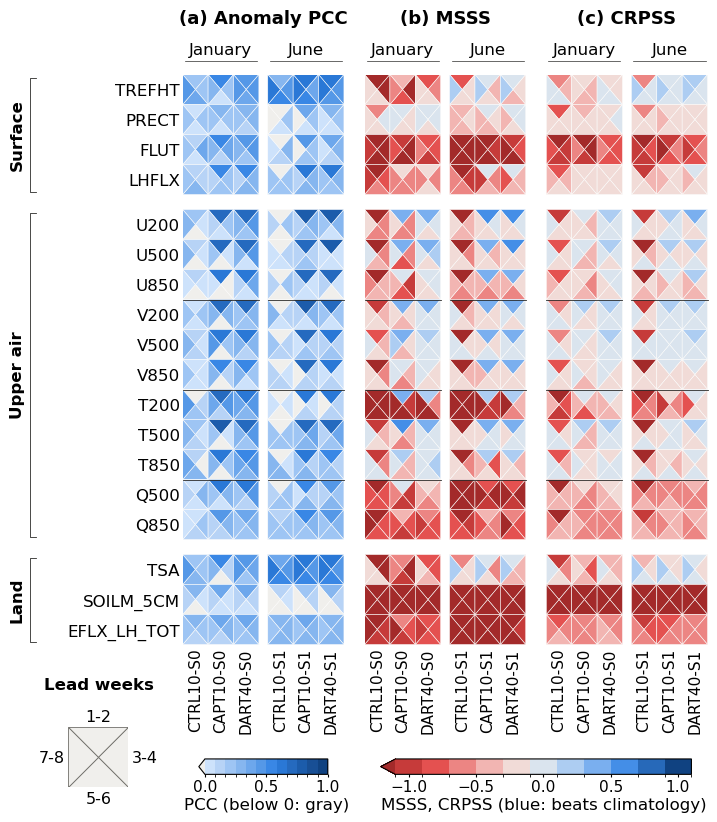

In [5]:
# ---- Figure settings ----
# Rows, grouped and ordered as below: one representative per family of variables that score
# alike (r >= 0.9 across experiments, windows, and metrics; e.g. TREFHT for TS/TG, 850 hPa for
# 700/925, FLUT for the radiation terms, LHFLX for SHFLX), TSA for land temperature, plus the
# mid/upper-level rows where DART40 beats CTRL10 and CAPT10 in MSSS and CRPSS (U500, V200, T500,
# Q500), and Q850 where it does not; PSL and Z left out (dominated by the DART surface-pressure
# loss; in the full list below). Any scored variables can be listed.
SUB_LIST = {"Surface": ("TREFHT", "PRECT", "FLUT", "LHFLX"),
            "Upper air": (
                "U200", "U500", "U850",
                "V200", "V500", "V850",
                "T200", "T500", "T850",
                "Q500", "Q850"
            ),
            "Land": ("TSA", "SOILM_5CM", "EFLX_LH_TOT")}
ROW_HEIGHT = 0.30  # inches per variable row
FIGURE_WIDTH = 7.2  # inches (7.2: double column)
FONTSIZE = 12  # pt; panel titles 1 pt larger, experiment names 1 pt smaller
KEY_SIZE = 0.60  # inches, side of the lead-week key (bottom left)
FIGURE_FORMAT = "pdf"  # "pdf" (vector) or "png"
FIGURE_DPI = 600  # png only

draw_scorecard("sub_list", SUB_LIST, row_height=ROW_HEIGHT, width=FIGURE_WIDTH, fontsize=FONTSIZE,
               key_size=KEY_SIZE, fmt=FIGURE_FORMAT, dpi=FIGURE_DPI)

### Every variable (`full_list`; supplement)

In [6]:
# ---- Figure settings ----
# Rows: every scored variable, grouped as in the user setup.
FULL_LIST = {"Surface": SURFACE, "Upper air": UPPER_AIR, "Land": LAND}
ROW_HEIGHT = 0.18  # inches per variable row (full page)
FIGURE_WIDTH = 7.2  # inches (7.2: double column)
FONTSIZE = 12  # pt; panel titles 1 pt larger, experiment names 1 pt smaller
KEY_SIZE = 0.60  # inches, side of the lead-week key (bottom left)
FIGURE_FORMAT = "pdf"  # "pdf" (vector) or "png"
FIGURE_DPI = 600  # png only

draw_scorecard("full_list", FULL_LIST, row_height=ROW_HEIGHT, width=FIGURE_WIDTH, fontsize=FONTSIZE,
               key_size=KEY_SIZE, fmt=FIGURE_FORMAT, dpi=FIGURE_DPI)

[FIGURE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/figure/fcst_window_scorecard/fig_window_scorecard_full_list_global.pdf
[CAPTION] Biweekly lead-window skill of the January (S0) and June (S1) hindcasts over the globe. Columns: CTRL10-S0, CAPT10-S0, and DART40-S0 (January); CTRL10-S1, CAPT10-S1, and DART40-S1 (June). Each cell is divided into four triangles, one per lead window after initialization: weeks 1-2 (top), 3-4 (right), 5-6 (bottom), and 7-8 (left). (a) Anomaly pattern correlation (PCC) of the window-mean anomalies (light gray: below 0). (b) Mean-square skill score of the ensemble-mean window means against the climatology forecast, MSSS = 1 - (RMSE/RMSE_clim)^2. (c) Skill score of the fair continuous ranked probability score of the ensemble against a climatological ensemble of the 16 climatology years, CRPSS = 1 - CRPS/CRPS_clim. In (b) and (c), blue cells beat climatology (score above 0) and red cells are worse than it. Rows: surface, PSL (sea-level pressure), TREFHT (2-m

## 5. Score table

In [7]:
display(
    scores.pivot_table(index=["region", "component", "variable", "season", "experiment"],
                       columns="window", values=["pcc", "msss", "crpss", "rmse", "rmse_clim", "crps", "crps_clim", "bias"], sort=False).round(3)
)

pcc                          \
window                                      week1-2 week3-4 week5-6 week7-8   
region component variable season experiment                                   
global atm       PSL      S0     CTRL10-S0    0.345   0.210   0.176   0.088   
                                 CAPT10-S0    0.808  -0.180  -0.353  -0.013   
                                 DART40-S0    0.760   0.494   0.129   0.043   
                          S1     CTRL10-S1   -0.533   0.071  -0.273   0.435   
                                 CAPT10-S1    0.761  -0.036  -0.126   0.459   
...                                             ...     ...     ...     ...   
       lnd       FSH      S0     CAPT10-S0    0.343   0.145   0.021   0.182   
                                 DART40-S0    0.341   0.162   0.084   0.192   
                          S1     CTRL10-S1    0.223   0.251   0.269   0.286   
                                 CAPT10-S1    0.350   0.296   0.283   0.292   
                                 DART40-S1    0.334   0.295   0.287   0.292   

                                               msss                          \
window                                      week1-2 week3-4 week5-6 week7-8   
region component variable season experiment                                   
global atm       PSL      S0     CTRL10-S0   -1.283  -0.418  -0.092  -0.509   
                                 CAPT10-S0    0.402  -1.232  -0.750  -0.492   
                                 DART40-S0   -3.371  -2.210  -1.561  -3.223   
                          S1     CTRL10-S1   -2.520  -0.678  -1.027   0.055   
                                 CAPT10-S1    0.457  -1.204  -0.873   0.049   
...                                             ...     ...     ...     ...   
       lnd       FSH      S0     CAPT10-S0   -0.798  -1.098  -1.058  -1.053   
                                 DART40-S0   -0.736  -0.925  -0.759  -0.944   
                          S1     CTRL10-S1   -1.591  -1.372  -1.273  -1.270   
                                 CAPT10-S1   -1.254  -1.111  -1.314  -1.351   
                                 DART40-S1   -1.074  -1.004  -1.134  -1.206   

                                              crpss          ...    crps  \
window                                      week1-2 week3-4  ... week5-6   
region component variable season experiment                  ...           
global atm       PSL      S0     CTRL10-S0   -0.753  -0.348  ...   2.934   
                                 CAPT10-S0    0.086  -0.615  ...   3.526   
                                 DART40-S0   -2.310  -1.640  ...   6.047   
                          S1     CTRL10-S1   -1.523  -0.395  ...   2.622   
                                 CAPT10-S1    0.018  -0.490  ...   2.470   
...                                             ...     ...  ...     ...   
       lnd       FSH      S0     CAPT10-S0   -0.796  -0.731  ...  11.913   
                                 DART40-S0   -0.651  -0.581  ...  10.717   
                          S1     CTRL10-S1   -0.996  -0.701  ...  10.876   
                                 CAPT10-S1   -0.872  -0.588  ...  10.825   
                                 DART40-S1   -0.659  -0.525  ...  10.351   

                                                    crps_clim                  \
window                                      week7-8   week1-2 week3-4 week5-6   
region component variable season experiment                                     
global atm       PSL      S0     CTRL10-S0    2.574     1.847   2.190   2.446   
                                 CAPT10-S0    2.590     1.847   2.190   2.446   
                                 DART40-S0    5.831     1.847   2.190   2.446   
                          S1     CTRL10-S1    1.869     1.779   1.409   1.690   
                                 CAPT10-S1    2.014     1.779   1.409   1.690   
...                                             ...       ...     ...     ...   
       lnd       FSH      S0     CAPT10-

## Notes: variables and references

| Row | Model | Reference | Climatology |
|---|---|---|---|
| PSL | `ts/daily_mean` (mean of the 00, 06, 12, 18Z states) | ERA5 daily (mean of the 00, 06, 12, 18Z analyses) | ERA5 daily |
| U, V, T, Q, Z at 200, 500, 700, 850, 925 hPa | 00Z state from `ts/daily_00z` (once-daily instantaneous output; day d = 00Z on d + 1) | ERA5 6-hourly at the same 00Z instants | ERA5 00Z |
| TREFHT | `ts/daily_mean` (00Z-24Z mean of the 6-h means) | ERA5 daily | ERA5 monthly |
| PRECT | `ts/daily_mean` | GPM IMERG (about 60S-60N) | IMERG daily |
| FLUT | `ts/daily_mean` (from the EAM h1 daily average) | NOAA interpolated OLR | NOAA OLR daily |
| TS | `ts/daily_mean` (00Z-24Z mean of the 6-h means) | ERA5 skin temperature, daily | ERA5 monthly |
| WSPD10 | EAM U10 (10-m wind speed), `ts/daily_mean` | ERA5 daily mean of the 6-hourly sqrt(u10² + v10²) | ERA5 daily |
| LHFLX, SHFLX | `ts/daily_mean` (upward positive) | ERA5 daily | ERA5 monthly |
| FSNS, FSDS, FLDS | `ts/daily_mean` (net shortwave, downward shortwave, downward longwave) | ERA5 daily | ERA5 monthly |
| TSA (land) | ELM 2-m air temperature | ERA5 TREFHT | ERA5 monthly |
| TG (land) | ELM ground temperature | ERA5 skin temperature TS | ERA5 monthly |
| SOILM_5CM (land) | ELM H2OSOI, thickness-weighted top 5 cm | ESA CCI | ESA CCI daily |
| EFLX_LH_TOT (land) | ELM latent heat flux | ERA5 LHFLX | ERA5 monthly |
| FSH (land) | ELM sensible heat flux | ERA5 SHFLX | ERA5 monthly |

Model daily means are labelled by the day they cover; the 00Z states keep their instant. Runs without `ts/daily_mean` get the same daily means from `ts/6hourly` (`util.model_daily`). The pressure-level rows are therefore instantaneous skill at 00Z, not daily-mean skill. PRECT uses IMERG rather than GPCP (the reference in `01_compute_and_plot_ens_ts`) because the daily climatology needs 2001-2017 and the GPCP daily archive covers only 2010-2015; IMERG covers about 60S-60N, so global PRECT scores refer to that band. Where the reference has gaps (IMERG, ESA CCI), both window means use only the days the reference is valid, and gridpoints with fewer than `MIN_DAYS` such days are left out. Units: PSL hPa, Z m, Q g kg-1, PRECT mm day-1, wind m s-1, fluxes W m-2. Surface net longwave (FLNS) is not scored: the ERA5 daily and 6-hourly FLNS files in the archive are corrupt (values 0-21 W m-2; FLNSC all zero), although the monthly FLNS is fine. ERA5 surface fluxes come from the reanalysis model's short forecasts, not direct observations.

Caches: per season, `reference_<variable>_window_means.nc` (reference and climatology window means, each climatology year's window means, valid days) `<experiment>_<variable>_window_means.nc` (each member's window means), and `above_ground_<level>hPa.nc` (the pressure-level masks); they record the climatology years, initial date, ensemble size, and (PSL, TREFHT) the daily-mean construction, and are rebuilt when those change. Valid caches are read in parallel (8 worker processes; `workers` in `build_window_means`). Table: `window_scores.csv` (`window_scores_centered.csv` and `_centered` figures with `REMOVE_MEAN_BIAS`; one row per season, variable, experiment, region, and window, with `rmse`, `rmse_clim`, `msss`, `bias`, `crps`, `crps_clim`, `crpss`, and `pcc`). For ERA5 TREFHT, TS, LHFLX, and SHFLX the climatological ensemble comes from monthly means, so its spread is somewhat too small and CRPSS is conservative there.